# Linear Algebra for Data Science 2026 — Lab 2, Core A
# Power iteration and inverse iteration

### <div align="right"> &copy; Rostyslav Hryniv, 2026, after V. Kuchynskyi & R. Hryniv, 2023 </div>

## Completed by:
*   First team member
*   Second team member

**Marked at the defence:** Core A is worth 2 points; the starred extensions at the end are one of three routes to the extension point (see the brief).

## Why this core

PageRank (Core B), the smoothing step in a graph neural network, and — later in the course — the leading principal component all need **one** eigenpair of a very large matrix that you can only *multiply by*. Power iteration is the algorithm that needs nothing more than $\mathbf{x}\mapsto A\mathbf{x}$. This core makes you implement it, **predict its speed before you run it**, find out where it breaks, and then use *inverse iteration with a shift* to reach the other eigenvalues.

**Uses:** Lecture 3.1 ($A^n = PD^nP^{-1}$, the Jordan asymptotics $n^k|\lambda|^n$, the role of $\kappa(P)$) and Lecture 3.2 (power iteration, inverse iteration). LU factorisation is a Module 0 prerequisite.

**Rules for this notebook**
* Inside `power_method` and `inverse_iteration` do **not** call `np.linalg.eig`, `np.linalg.eigvals`, `scipy.linalg.eig` or anything that calls them. You may use them elsewhere to *check* your results.
* Never call `np.linalg.inv` anywhere in this notebook. If you need $P^{-1}$ applied to something, solve a system.
* Every number you report must be reproduced by `Restart & Run All`.

In [14]:
import sys, numpy as np, scipy, scipy.linalg as sla, matplotlib
import matplotlib.pyplot as plt
print('python', sys.version.split()[0], '| numpy', np.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)
rng = np.random.default_rng(2026)   # do not change the seed: the defence uses your numbers

python 3.14.7 | numpy 2.5.3 | scipy 1.18.1 | matplotlib 3.11.2


### Two provided helpers

`sin_angle(u, v)` measures how far apart two *directions* are. It ignores length and sign (and, for complex vectors, any unimodular factor), so it is the right error measure for an eigenvector.

`similar_matrix(eigvals, P)` returns $A = P\,\mathrm{diag}(\text{eigvals})\,P^{-1}$ **without** forming $P^{-1}$: from $AP = PD$ we get $P^\top A^\top = (PD)^\top$, which is one linear solve.

In [15]:
def sin_angle(u, v):
    # sine of the angle between span{u} and span{v}; accurate for small angles
    u = u / np.linalg.norm(u)
    v = v / np.linalg.norm(v)
    return np.linalg.norm(u - v * np.vdot(v, u))

def similar_matrix(eigvals, P):
    # A = P diag(eigvals) P^{-1}, computed by one solve instead of an inverse
    PD = P * np.asarray(eigvals)[None, :]          # scales column j of P by eigvals[j]
    return np.linalg.solve(P.T, PD.T).T

def random_orthogonal(n):
    Q, R = np.linalg.qr(rng.standard_normal((n, n)))
    return Q * np.sign(np.diag(R))                  # sign fix: a uniformly random orthogonal Q

---
## 1. Power iteration

### 1.1 The idea, recalled
Let $A$ be a diagonalisable $k\times k$ matrix with eigenvalues ordered so that $|\lambda_1| > |\lambda_2| \ge \dots \ge |\lambda_k|$ (so $\lambda_1$ is real and simple when $A$ is real) and eigenvectors $\mathbf{v}_1,\dots,\mathbf{v}_k$. Write $\mathbf{x}_0 = c_1\mathbf{v}_1 + \dots + c_k\mathbf{v}_k$ with $c_1 \ne 0$. Then
$$
A^n\mathbf{x}_0 = \lambda_1^n\Bigl[c_1\mathbf{v}_1 + c_2\Bigl(\tfrac{\lambda_2}{\lambda_1}\Bigr)^n\mathbf{v}_2 + \dots + c_k\Bigl(\tfrac{\lambda_k}{\lambda_1}\Bigr)^n\mathbf{v}_k\Bigr],
$$
so the direction of $A^n\mathbf{x}_0$ approaches $\mathrm{span}\{\mathbf{v}_1\}$, and the error shrinks by roughly $|\lambda_2/\lambda_1|$ per step. Normalising at each step avoids overflow:
$$
\mathbf{x}_n := \frac{A\mathbf{x}_{n-1}}{\|A\mathbf{x}_{n-1}\|}, \qquad \lambda_1 \approx \mu_n := \mathbf{x}_n^{*} A\,\mathbf{x}_n \quad(\text{the Rayleigh quotient}).
$$

**When to stop.** Do *not* stop when $\|\mathbf{x}_n - \mathbf{x}_{n-1}\|$ is small: if $\lambda_1 < 0$, the vector flips sign at every step and never settles, although its *direction* has converged. Stop instead when the **residual** is small,
$$
\|A\mathbf{x}_n - \mu_n\mathbf{x}_n\| \le \texttt{tol}\cdot\|A\|_F .
$$
(Scaling by $\|A\|_F$, computed once, makes the test independent of units. Do not divide by $\|A\mathbf{x}_n\|$ instead: that breaks down when the eigenvalue you are after is $0$.)
A small residual says that $(\mu_n, \mathbf{x}_n)$ is an exact eigenpair of a matrix very close to $A$ — the most you can ask of any floating-point method.

### 1.2 Implement `power_method`
Return the eigenvalue estimate, the unit eigenvector estimate and a history: the Rayleigh quotients and the residuals at every step. Use `np.vdot` for $\mathbf{x}^*\mathbf{y}$ so that complex input also works.

In [16]:
def power_method(A, x0=None, tol=1e-10, max_iter=1000):
    '''
    Dominant eigenpair of A by power iteration.

    Args:
        A        : (k, k) array
        x0       : starting vector; random (from rng) if None
        tol      : stop when ||A x - mu x|| <= tol * ||A||_F
        max_iter : maximum number of matrix-vector products
    Returns:
        mu   : eigenvalue estimate (Rayleigh quotient)
        x    : unit eigenvector estimate
        hist : dict with arrays 'mu' and 'res', one entry per iteration
    ''' 
    
    A = np.asarray(A)
    k = A.shape[0]

    if x0 is None:
        x = rng.random(k)
    else:
        x = np.asarray(x0).copy()

    x = x / np.linalg.norm(x)
    A_norm = np.linalg.norm(A)

    hist = {'mu': [], 'res': []}

    for _ in range(max_iter):
        y = A @ x
        y_norm = np.linalg.norm(y)

        x = y / y_norm
        mu = np.vdot(x, A @ x)

        residual = np.linalg.norm(A @ x - mu * x)

        hist['mu'].append(mu)
        hist['res'].append(residual)

        if residual <= tol * A_norm:
            break

    return mu, x, hist

### 1.3 Test it
The checker compares with `np.linalg.eig`. Its tolerances are matched to `tol`: a residual of $10^{-10}$ cannot give 15 correct digits, so do not tighten them.

The test matrices are chosen on purpose: `A1` has a **negative** dominant eigenvalue, `A2` is symmetric and indefinite, `A3` is non-symmetric with prescribed real eigenvalues.

In [17]:
def check_dominant(A, mu, x, rtol=1e-6):
    lam, V = np.linalg.eig(A)
    i = np.argmax(np.abs(lam))
    assert abs(mu - lam[i]) <= rtol * abs(lam[i]), f'eigenvalue {mu} vs {lam[i]}'
    assert sin_angle(x, V[:, i]) <= rtol, f'eigenvector off by sin(angle) = {sin_angle(x, V[:, i]):.1e}'
    print(f'passed: mu = {complex(mu).real:+.10f}')

A1 = np.array([[0., 1.], [-2., -3.]])
M = rng.standard_normal((6, 6)); A2 = M + M.T
A3 = similar_matrix([-5., 3., 2., 1., 0.5], rng.standard_normal((5, 5)))
for A in (A1, A2, A3):
    mu, x, hist = power_method(A)
    check_dominant(A, mu, x)
    print('   iterations:', len(hist['res']))

passed: mu = -2.0000000006
   iterations: 30
passed: mu = -5.0027417669
   iterations: 169
passed: mu = -5.0000000004
   iterations: 55


**Question 1.3.** Last year's tests used matrices `10*np.random.rand(n, n)`. Explain why even a buggy implementation that cannot cope with a negative dominant eigenvalue would pass all of those tests. *(Hint: the entries are positive; Lecture 3.2, Perron–Frobenius.)*

---
**Your answer here**

The matrices generated by `10 * np.random.rand(n, n)` have strictly positive entries in a range([0,10]). By the Perron–Frobenius theorem, a matrix with strictly positive entries has a positive dominant eigenvalue. Therefore, the dominant eigenvalue could never be negative in these tests, so the negative dominant eigenvalue was never exposed.
---



### 1.4 Predict the speed, then measure it

This is the main experiment of the core. Take $k = 50$, an orthogonal $Q$, and
$$
A_r = Q\,\mathrm{diag}(1,\ r,\ \text{48 values spread evenly in } [-0.3r, 0.3r])\,Q^\top, \qquad r \in \{0.5,\ 0.9,\ 0.99\}.
$$
The dominant eigenvector is $\mathbf{v}_1 = \mathbf{q}_1$, the first column of $Q$.

**(a) Predict first.** For each $r$, how many iterations should it take for $\sin\angle(\mathbf{x}_n, \mathbf{v}_1)$ to fall from about $1$ to $10^{-8}$? Write the formula and the three numbers *before* running anything.

---
**Your answer here**

n = ln(10⁻⁸) / ln(r) = 8·ln(10) / (−ln r)
r(0.5) = 27
r(0.9) = 175
r(0.99) = 1833
---




**(b) Measure.** Write `power_errors(A, v1, lam1, n_steps, x0)` that runs exactly `n_steps` normalised iterations from `x0` and returns two arrays: the eigenvector error $\sin\angle(\mathbf{x}_n,\mathbf{v}_1)$ and the eigenvalue error $|\mu_n - \lambda_1|$. Plot both against $n$ on a log scale for the three values of $r$, with the reference lines $r^n$. Use the **same** `x0` for all runs. Report the measured iteration counts next to your predictions.

r = 0.5: predicted 27 iterations, measured 26 iterations
r = 0.9: predicted 175 iterations, measured 166 iterations
r = 0.99: predicted 1833 iterations, measured 1734 iterations


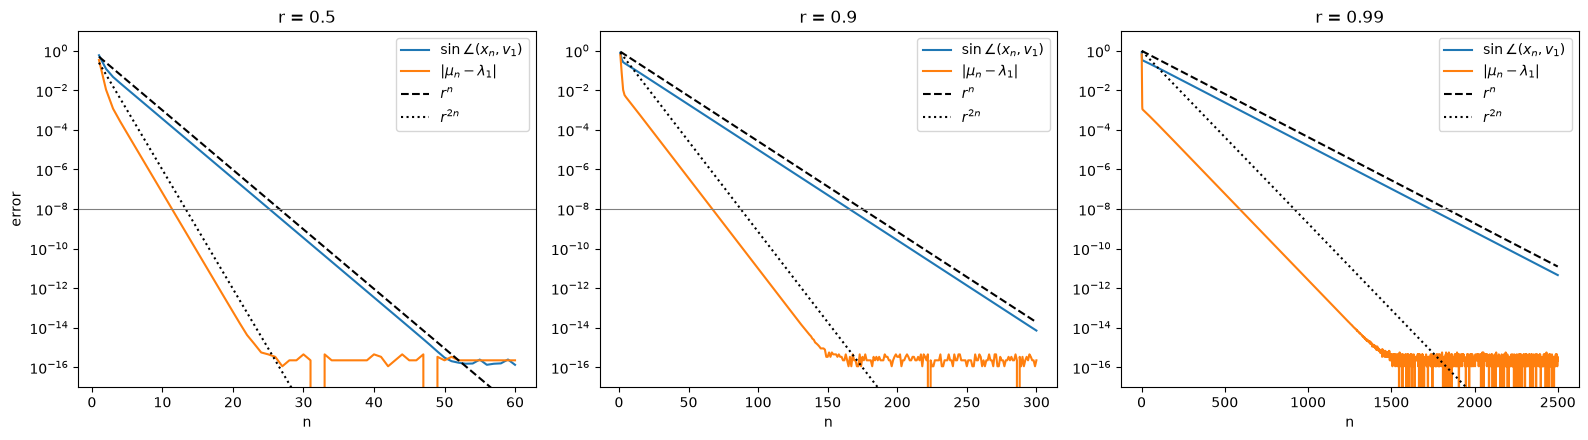

In [18]:
def power_errors(A, v1, lam1, n_steps, x0):
    # YOUR CODE HERE
    x = np.asarray(x0).copy()
    x = x / np.linalg.norm(x)

    vec_err = np.zeros(n_steps)
    val_err = np.zeros(n_steps)

    for n in range(n_steps):
        y = A @ x
        x = y / np.linalg.norm(y)
        mu = np.vdot(x, A @ x)

        vec_err[n] = sin_angle(x, v1)
        val_err[n] = abs(mu - lam1)

    return vec_err, val_err

k = 50
Q = random_orthogonal(k)
x0 = rng.standard_normal(k)
# YOUR CODE HERE: build A_r for r in (0.5, 0.9, 0.99), run power_errors, plot, report
r_values = (0.5, 0.9, 0.99)
n_steps = {0.5: 60, 0.9: 300, 0.99: 2500}
v1 = Q[:, 0]
lam1 = 1.0

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, r in zip(axes, r_values):
    eigs = np.concatenate(([1.0, r], np.linspace(-0.3 * r, 0.3 * r, k - 2)))
    A_r = Q @ np.diag(eigs) @ Q.T

    vec_err, val_err = power_errors(A_r, v1, lam1, n_steps[r], x0)
    n = np.arange(1, n_steps[r] + 1)

    predicted = int(np.ceil(np.log(1e-8) / np.log(r)))
    measured = np.argmax(vec_err <= 1e-8) + 1

    print(f'r = {r}: predicted {predicted} iterations, measured {measured} iterations')

    ax.semilogy(n, vec_err, label=r'$\sin\angle(x_n, v_1)$')
    ax.semilogy(n, val_err, label=r'$|\mu_n - \lambda_1|$')
    ax.semilogy(n, r ** n, 'k--', label=r'$r^n$')
    ax.semilogy(n, r ** (2 * n), 'k:', label=r'$r^{2n}$')
    ax.axhline(1e-8, color='gray', linewidth=0.8)
    ax.set_ylim(1e-17, 10)
    ax.set_title(f'r = {r}')
    ax.set_xlabel('n')
    ax.legend()

axes[0].set_ylabel('error')
plt.tight_layout()
plt.show()

**(c) Two observations to explain.**
1. For this symmetric $A_r$ the eigenvalue error falls like $r^{2n}$ — twice as fast as the eigenvector error. You do not need to prove this (Module 4 will), but describe what you see and say why it is good news for PageRank-style uses.
2. Now repeat (b) for $r = 0.9$ only, with $A = P\,\mathrm{diag}(\dots)\,P^{-1}$ built by `similar_matrix`, where $P = U\,\mathrm{diag}(s)\,V^\top$ has orthogonal $U, V$ and singular values $s$ spread logarithmically from $1$ to $10^{-3}$, so that $\kappa(P) = 10^3$. Did the **rate** change? Did anything else change? Relate this to the role of $\kappa(P)$ in Lecture 3.1.

kappa(P) = 1000.0000000000095
Q (symmetric): sin < 1e-8 after 166 steps, eigenvector rate 0.9000, eigenvalue rate 0.8100, sin at n=1: 7.99e-01, |mu-lam| at n=1: 6.13e-01
P (kappa = 1e3): sin < 1e-8 after 164 steps, eigenvector rate 0.9000, eigenvalue rate 0.8997, sin at n=1: 9.51e-01, |mu-lam| at n=1: 8.92e-01


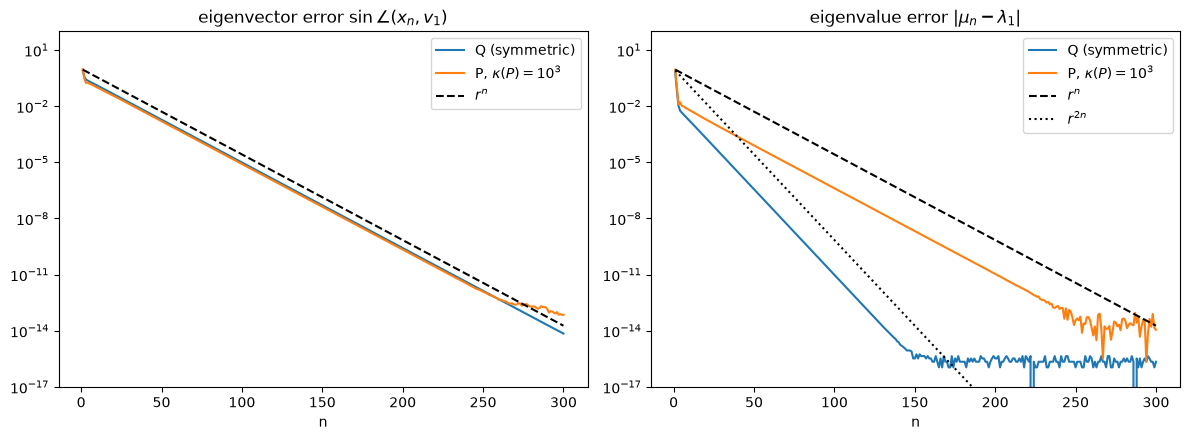

In [19]:
# YOUR CODE HERE for (c)2
r = 0.9
steps = 300
eigs = np.concatenate(([1.0, r], np.linspace(-0.3 * r, 0.3 * r, k - 2)))

# symmetric case again, to compare with
A_sym = Q @ np.diag(eigs) @ Q.T
vec_sym, val_sym = power_errors(A_sym, Q[:, 0], 1.0, steps, x0)

# non-symmetric case with kappa(P) = 1e3
U = random_orthogonal(k)
V = random_orthogonal(k)
s = np.logspace(0, -3, k)
P = (U * s) @ V.T
print('kappa(P) =', np.linalg.cond(P))

A_P = similar_matrix(eigs, P)
vec_P, val_P = power_errors(A_P, P[:, 0], 1.0, steps, x0)

n = np.arange(1, steps + 1)
for name, vec_err, val_err in (('Q (symmetric)', vec_sym, val_sym), ('P (kappa = 1e3)', vec_P, val_P)):
    measured = np.argmax(vec_err <= 1e-8) + 1
    # slope of log(error) on the straight part = rate per step
    rate_vec = np.exp(np.polyfit(n[50:150], np.log(vec_err[50:150]), 1)[0])
    rate_val = np.exp(np.polyfit(n[20:100], np.log(val_err[20:100]), 1)[0])
    print(f'{name}: sin < 1e-8 after {measured} steps, '
          f'eigenvector rate {rate_vec:.4f}, eigenvalue rate {rate_val:.4f}, '
          f'sin at n=1: {vec_err[0]:.2e}, |mu-lam| at n=1: {val_err[0]:.2e}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].semilogy(n, vec_sym, label='Q (symmetric)')
axes[0].semilogy(n, vec_P, label=r'P, $\kappa(P)=10^3$')
axes[0].semilogy(n, r ** n, 'k--', label=r'$r^n$')
axes[0].set_title(r'eigenvector error $\sin\angle(x_n, v_1)$')

axes[1].semilogy(n, val_sym, label='Q (symmetric)')
axes[1].semilogy(n, val_P, label=r'P, $\kappa(P)=10^3$')
axes[1].semilogy(n, r ** n, 'k--', label=r'$r^n$')
axes[1].semilogy(n, r ** (2 * n), 'k:', label=r'$r^{2n}$')
axes[1].set_title(r'eigenvalue error $|\mu_n - \lambda_1|$')

for ax in axes:
    ax.set_xlabel('n')
    ax.set_ylim(1e-17, 1e2)
    ax.legend()
plt.tight_layout()
plt.show()

---
**Your answer here**

1. The eigenvector error goes along the $r^n$ line, but the eigenvalue error goes along $r^{2n}$ (rate 0.81 for r = 0.9), so it gets to machine precision in about half the steps. For PageRank this is good because every step is a multiplication by a huge matrix, so we get the eigenvalue accurately much earlier.

2. The rate of the eigenvector error did not change (still 0.9, 164 steps vs 166), because it depends only on $\lambda_2/\lambda_1$. What changed is that the eigenvalue error now falls only like $r^n$, not $r^{2n}$, and the errors stop at a higher level (about $10^{-13}$).

---

### 1.5 Reasons to fail
For each case below: explain *why* the method fails or slows down, give your own $3\times 3$ example, run `power_method` on it, and describe what you see (no convergence? convergence to the wrong thing? very slow convergence?). Look at `hist['res']` and `hist['mu']`, not only at the final output.

1. The dominant eigenvalues of a real matrix are a complex-conjugate pair.
2. $\lambda_1 = -\lambda_2$ (two real eigenvalues of equal modulus).
3. The dominant eigenvalue is defective: a Jordan block. *Hint:* it does converge — at what rate? Compare with the asymptotics $n^k|\lambda|^n$ from Lecture 3.1. Plot the eigenvector error, the eigenvalue error and the residual against $n$; they do **not** fall at the same rate. What does that tell you about trusting a small residual?
4. The starting vector has $c_1 = 0$. First run `power_method` with its defaults on $A = Q\,\mathrm{diag}(2,1,0.5)\,Q^\top$ (random orthogonal $Q$) and $\mathbf{x}_0 = \mathbf{q}_2$: why does it stop at once, and with what answer? Then switch the stopping test off (`tol=0`, `max_iter=120`) and compare two runs: $A = \mathrm{diag}(2, 1, 0.5)$ with $\mathbf{x}_0 = \mathbf{e}_2$, and $QDQ^\top$ with $\mathbf{x}_0 = \mathbf{q}_2$. They behave differently. Explain why, and predict roughly how many iterations the second one needs before it "notices" $\mathbf{v}_1$.

case 1: eigenvalues [1. +2.j 1. -2.j 0.5+0.j]
   iterations: 1000 | last mu: [1. 1. 1. 1. 1.] | last res: [2. 2. 2. 2. 2.]
case 2: eigenvalues [ 2.+0.j  1.+0.j -2.+0.j]
   iterations: 1000 | last mu: [-1.2553 -1.2553 -1.2553 -1.2553 -1.2553] | last res: [1.557 1.557 1.557 1.557 1.557]
case 3: with default tol it stops after 1000 iterations


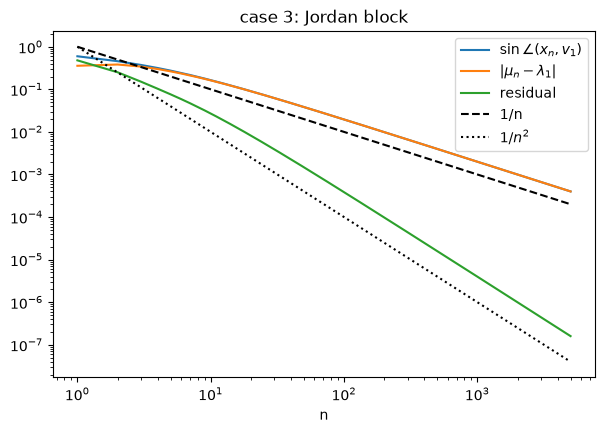

case 4: default run stops after 1 iteration(s), mu = 0.9999999999999996 , res = 2.665835984225005e-16
   diag, x0 = e2: final mu = 1.0
   QDQ^T, x0 = q2: final mu = 1.9999999999999996 | mu > 1.5 first at step 54


In [20]:
# YOUR CODE HERE: one experiment per case
x3 = np.array([1.0, 1.0, 1.0])

# case 1: complex pair 1 +- 2i, and 0.5
A_c = np.array([[1., -2., 0.],
                [2.,  1., 0.],
                [0.,  0., 0.5]])
mu, x, hist = power_method(A_c, x3)
print('case 1: eigenvalues', np.linalg.eigvals(A_c))
print('   iterations:', len(hist['res']), '| last mu:', np.round(hist['mu'][-5:], 4),
      '| last res:', np.round(hist['res'][-5:], 4))

# case 2: lambda1 = -lambda2
Q3 = random_orthogonal(3)
A_pm = Q3 @ np.diag([2., -2., 1.]) @ Q3.T
mu, x, hist = power_method(A_pm, x3)
print('case 2: eigenvalues', np.linalg.eigvals(A_pm))
print('   iterations:', len(hist['res']), '| last mu:', np.round(hist['mu'][-5:], 4),
      '| last res:', np.round(hist['res'][-5:], 4))

# case 3: Jordan block for lambda = 2
A_J = np.array([[2., 1., 0.],
                [0., 2., 0.],
                [0., 0., 1.]])
n_J = 5000
vec_J, val_J = power_errors(A_J, np.array([1., 0., 0.]), 2.0, n_J, x3)
mu, x, hist = power_method(A_J, x3, tol=0, max_iter=n_J)
print('case 3: with default tol it stops after', len(power_method(A_J, x3)[2]['res']), 'iterations')
n = np.arange(1, n_J + 1)
plt.figure(figsize=(7, 4.5))
plt.loglog(n, vec_J, label=r'$\sin\angle(x_n, v_1)$')
plt.loglog(n, val_J, label=r'$|\mu_n - \lambda_1|$')
plt.loglog(n, hist['res'], label='residual')
plt.loglog(n, 1 / n, 'k--', label='1/n')
plt.loglog(n, 1 / n**2, 'k:', label=r'$1/n^2$')
plt.xlabel('n')
plt.title('case 3: Jordan block')
plt.legend()
plt.show()

# case 4: c1 = 0
A_Q = Q3 @ np.diag([2., 1., 0.5]) @ Q3.T
mu, x, hist = power_method(A_Q, Q3[:, 1])
print('case 4: default run stops after', len(hist['res']), 'iteration(s), mu =', mu, ', res =', hist['res'][-1])

A_D = np.diag([2., 1., 0.5])
_, _, hist_D = power_method(A_D, np.array([0., 1., 0.]), tol=0, max_iter=120)
_, _, hist_Q = power_method(A_Q, Q3[:, 1], tol=0, max_iter=120)
mu_D = np.array(hist_D['mu'])
mu_Q = np.array(hist_Q['mu'])
print('   diag, x0 = e2: final mu =', mu_D[-1])
print('   QDQ^T, x0 = q2: final mu =', mu_Q[-1], '| mu > 1.5 first at step', np.argmax(mu_Q > 1.5) + 1)

---
**Your answer here**

1. A real $x_n$ cannot converge to a complex eigenvector, and both $1 \pm 2i$ have the same modulus, so $x_n$ just keeps rotating in their plane. No convergence: after 1000 steps $\mu_n = 1$ (only the real part) and the residual stays at 2.

2. With $\lambda_1 = -\lambda_2$ neither term wins, so $x_n$ jumps between two directions in $\mathrm{span}\lbrace v_1, v_2 \rbrace$. $\mu_n$ settles at $-1.2553$, which is not an eigenvalue, and the residual stays at 1.557, so it converges to the wrong thing but the residual shows it.

3. For a Jordan block $A^n x_0 \sim n\lambda^n v_1 + \lambda^n(\dots)$, so the error falls only like $1/n$ instead of geometrically. Very slow: after 5000 steps the eigenvector and eigenvalue errors are still about $4\cdot10^{-4}$, but the residual falls like $1/n^2$ and is already $10^{-7}$. So a small residual does not mean an accurate eigenvector when the eigenvalue is defective.

4. $q_2$ is an exact eigenvector, so the residual is $\approx 10^{-16}$ at the first step and it stops at once with $\mu = 1$, the wrong eigenvalue. For diag(2,1,0.5) with $e_2$ the first component is exactly 0 and stays 0 forever, so $\mu = 1$ all 120 steps. For $QDQ^\top$ rounding puts a $c_1 \approx 10^{-16}$ component in, which grows like $2^n$, so it needs about $\log_2(10^{16}) \approx 53$ steps; we measured 54.

---

---
## 2. Inverse iteration with a shift

### 2.1 The idea
If $A\mathbf{v} = \lambda\mathbf{v}$ then $(A - \mu I)^{-1}\mathbf{v} = (\lambda - \mu)^{-1}\mathbf{v}$. So the eigenvalue of $A$ **closest to the shift** $\mu$ becomes the *dominant* eigenvalue of $(A-\mu I)^{-1}$, and power iteration on $(A-\mu I)^{-1}$ finds it. The per-step rate is
$$
\frac{|\lambda_* - \mu|}{|\lambda_{**} - \mu|},
$$
where $\lambda_*$ is the closest eigenvalue and $\lambda_{**}$ the second-closest.

You never form $(A-\mu I)^{-1}$. Each step **solves** $(A - \mu I)\mathbf{y} = \mathbf{x}_{n-1}$. Factorise $A - \mu I = LU$ once with `scipy.linalg.lu_factor`, then call `scipy.linalg.lu_solve` at every step.

### 2.2 Implement `inverse_iteration`
Return the eigenvalue **of $A$** (the Rayleigh quotient $\mathbf{x}^*A\mathbf{x}$, not of the inverse), the unit eigenvector and the same history as before, with the same residual stopping rule applied to $A$.

In [21]:
def inverse_iteration(A, mu, x0=None, tol=1e-10, max_iter=500):
    '''
    Eigenpair of A for the eigenvalue closest to the shift mu.
    One LU factorisation of A - mu I, reused at every step.
    Returns (lam, x, hist) as in power_method.
    '''
    # YOUR CODE HERE
    A = np.asarray(A)
    k = A.shape[0]

    if x0 is None:
        x = rng.random(k)
    else:
        x = np.asarray(x0).copy()

    x = x / np.linalg.norm(x)
    A_norm = np.linalg.norm(A)

    lu, piv = sla.lu_factor(A - mu * np.eye(k))

    hist = {'mu': [], 'res': []}

    for _ in range(max_iter):
        y = sla.lu_solve((lu, piv), x)
        x = y / np.linalg.norm(y)

        lam = np.vdot(x, A @ x)
        residual = np.linalg.norm(A @ x - lam * x)

        hist['mu'].append(lam)
        hist['res'].append(residual)

        if residual <= tol * A_norm:
            break

    return lam, x, hist

**Question 2.2.** State the cost of your implementation in flops, to leading order, for a $k\times k$ matrix and $m$ iterations. Compare with (i) calling `np.linalg.solve(A - mu*I, x)` inside the loop and (ii) forming `inv(A - mu*I)` once and multiplying. Why is (ii) still worse than your version, even though its cost per step is also $O(k^2)$?

---
**Your answer here**

The LU factorisation is done once and costs about $\frac{2}{3}k^3$ flops. Each step then does one `lu_solve` ($2k^2$) and two products with $A$ ($2k^2$ each), so the total is about $\frac{2}{3}k^3 + 6mk^2$.

(i) `np.linalg.solve` inside the loop does a new LU every step, so it costs about $\frac{2}{3}mk^3$, which is much worse for large $k$.

(ii) Forming the inverse costs about $2k^3$, three times more than LU, and after that each step is $2k^2$, the same as `lu_solve`. It is still worse because it is less accurate: $A - \mu I$ is almost singular when $\mu$ is close to an eigenvalue (that is the whole point of the shift), and an explicitly computed inverse of such a matrix has large errors, while solving with LU is backward stable.

---

### 2.3 Find all eigenvalues of a test matrix
Let $D = \mathrm{diag}(0, 1, \dots, 9)$, let $P$ be a random $10\times10$ matrix, and $A = PDP^{-1}$ (use `similar_matrix`).

**(a)** Explain why the diagonal entries of $D$ are the eigenvalues of $A$ and the columns of $P$ are corresponding eigenvectors.

**(b)** With the shifts $\mu_j = j + 0.3$, $j = 0,\dots,9$, find all ten eigenpairs. Check each against the corresponding column of $P$ with `sin_angle`.

**(c)** Predict the per-step rate for $\mu = j + 0.3$ and for $\mu = j + 0.49$, then measure both for one $j$ of your choice from the history. Which eigenvalue does $\mu = j + 0.5$ find, and why is that shift a bad idea?

---
**Your answer here**

**(a)** From $A = PDP^{-1}$ we get $AP = PD$. Column $j$ of this says $A\mathbf{p}_j = d_j\mathbf{p}_j$, and $\mathbf{p}_j \ne \mathbf{0}$ because $P$ is invertible (a random matrix is invertible with probability 1). So each $d_j = j$ is an eigenvalue of $A$ and $\mathbf{p}_j$ is its eigenvector.

---

In [22]:
D_vals = np.arange(10.)
P10 = rng.standard_normal((10, 10))
A10 = similar_matrix(D_vals, P10)
# YOUR CODE HERE

for j in range(10):
    lam, x, hist = inverse_iteration(A10, j + 0.3)
    print(f'mu = {j + 0.3:.1f}: lambda = {lam:.10f}, iterations = {len(hist["res"])}, '
          f'sin angle with P[:, {j}] = {sin_angle(x, P10[:, j]):.1e}')

def measured_rate(res):
    res = np.array(res)
    n = np.arange(len(res))
    m = len(res) // 2
    return np.exp(np.polyfit(n[2:m], np.log(res[2:m]), 1)[0])

j = 4
x_start = rng.standard_normal(10)
for d in (0.3, 0.49):
    lam, x, hist = inverse_iteration(A10, j + d, x0=x_start, max_iter=2000)
    print(f'mu = {j + d}: predicted rate {d / (1 - d):.4f}, measured rate {measured_rate(hist["res"]):.4f}, '
          f'iterations = {len(hist["res"])}, lambda = {lam:.8f}')

lam, x, hist = inverse_iteration(A10, j + 0.5, x0=x_start)
print(f'mu = {j + 0.5}: iterations = {len(hist["res"])}, last mu: {np.round(hist["mu"][-4:], 4)}, '
      f'last res: {np.round(hist["res"][-4:], 4)}')

mu = 0.3: lambda = 0.0000000028, iterations = 24, sin angle with P[:, 0] = 2.3e-09
mu = 1.3: lambda = 1.0000000002, iterations = 21, sin angle with P[:, 1] = 1.6e-09
mu = 2.3: lambda = 1.9999999995, iterations = 21, sin angle with P[:, 2] = 1.8e-09
mu = 3.3: lambda = 3.0000000006, iterations = 22, sin angle with P[:, 3] = 3.1e-09
mu = 4.3: lambda = 4.0000000010, iterations = 18, sin angle with P[:, 4] = 2.6e-09
mu = 5.3: lambda = 4.9999999982, iterations = 23, sin angle with P[:, 5] = 2.6e-09
mu = 6.3: lambda = 6.0000000005, iterations = 25, sin angle with P[:, 6] = 3.4e-09
mu = 7.3: lambda = 7.0000000005, iterations = 22, sin angle with P[:, 7] = 2.1e-09
mu = 8.3: lambda = 8.0000000008, iterations = 25, sin angle with P[:, 8] = 1.9e-09
mu = 9.3: lambda = 8.9999999986, iterations = 13, sin angle with P[:, 9] = 3.2e-09
mu = 4.3: predicted rate 0.4286, measured rate 0.4332, iterations = 24, lambda = 4.00000000
mu = 4.49: predicted rate 0.9608, measured rate 0.9618, iterations = 492, lamb

---
**Your answer here**

**(b)** All ten shifts found the right eigenvalue in 13–25 iterations, with eigenvalue error about $10^{-9}$ and $\sin\angle$ with the column of $P$ about $2\text{–}3\cdot10^{-9}$, which is what $\texttt{tol} = 10^{-10}$ allows.

**(c)** For $\mu = j + 0.3$ the closest eigenvalue is $j$ (distance 0.3) and the next one is $j+1$ (distance 0.7), so the rate is $0.3/0.7 \approx 0.43$. For $\mu = j + 0.49$ it is $0.49/0.51 \approx 0.96$. For $j = 4$ I measured $0.433$ (24 iterations) and $0.962$ (492 iterations), close to the predictions.

$\mu = j + 0.5$ is exactly in the middle of $j$ and $j+1$, so $(A - \mu I)^{-1}$ has eigenvalues $-2$ and $2$ of the same modulus. This is case 2 of §1.5: it finds neither of them, $x_n$ jumps between two directions and $\mu_n$ alternates between 4.589 and 4.680 until max_iter.

---

### 2.4 A shift that is *too* good
Take $\mu = 4 + 10^{-12}$. Compute $\kappa(A_{10} - \mu I)$ with `np.linalg.cond`. By everything you learned in Modules 1–2, solving with this matrix should be hopeless. Run `inverse_iteration` anyway and report the number of iterations and the accuracy of the eigenvector. Then explain, in your own words, why the huge condition number does no harm here. *(Hint: the solution $\mathbf{y}$ is badly wrong in length; in which direction is it wrong?)*

In [23]:
# YOUR CODE HERE
mu = 4 + 1e-12
print('cond(A10 - mu I) =', np.linalg.cond(A10 - mu * np.eye(10)))

lam, x, hist = inverse_iteration(A10, mu)
print('iterations:', len(hist['res']))
print('lambda =', lam, ', error =', abs(lam - 4))
print('sin angle with P[:, 4] =', sin_angle(x, P10[:, 4]))

x_start = rng.standard_normal(10)
y = sla.solve(A10 - mu * np.eye(10), x_start)
print('||y|| =', np.linalg.norm(y), ', sin angle of y with P[:, 4] =', sin_angle(y, P10[:, 4]))

cond(A10 - mu I) = 85909015437984.27
iterations: 1
lambda = 4.000000000000682 , error = 6.821210263296962e-13
sin angle with P[:, 4] = 4.565760138717216e-12
||y|| = 1505541309355.2124 , sin angle of y with P[:, 4] = 2.504085413143998e-12


---
**Your answer here**

$\kappa(A_{10} - \mu I) \approx 8.6\cdot10^{13}$, so by Modules 1–2 the solution $\mathbf{y}$ could be wrong in almost all digits. But inverse iteration stops after **1** iteration with eigenvalue error $7\cdot10^{-13}$ and $\sin\angle$ with $\mathbf{p}_4$ about $5\cdot10^{-12}$.

The huge condition number comes from the one tiny eigenvalue $10^{-12}$ of $A - \mu I$. The error in $\mathbf{y}$ is big ($\|\mathbf{y}\| \approx 1.5\cdot10^{12}$, and its length is not accurate), but this error is almost all in the direction of $\mathbf{p}_4$, the same direction as the true $\mathbf{y}$. So only the length of $\mathbf{y}$ is wrong, not its direction, and we normalise $\mathbf{y}$ anyway, so the error does no harm.

---

---
## 3. Conclusions
In a few sentences: what did you learn, what was harder than expected, and which result surprised you? If you hit a wall you could not get past, describe it here **and** in your `README` — an explained wall is worth more at the defence than a clean output you cannot explain.

---
**Your answer here**

We learned that power iteration only needs $A\mathbf{x}$ and that its speed can be predicted from $|\lambda_2/\lambda_1|$ before running it, and the measured counts were close to the predictions. Harder than expected were the failure cases, especially the Jordan block, where the residual is small but the eigenvector is still far off, so a small residual cannot always be trusted. The most surprising result was 2.4: a matrix with condition number $10^{13}$ still gave the eigenvector in one step, because the error only goes into the length of $\mathbf{y}$.

---

---
# ★ Extensions
Do **at most one** extension for the whole lab (A1, A2 here, or B1 in the Core B notebook). The point is awarded for **a defended finding**: end your extension with a short paragraph headed *Finding* that states what you found and why.

## ★ A1. The QR algorithm: what `np.linalg.eig` builds on
Starting from $A_1 = A$, repeat: factor $A_k = Q_kR_k$, set $A_{k+1} := R_kQ_k$. Under mild assumptions $A_k$ tends to an upper-triangular matrix with the eigenvalues of $A$ on the diagonal.

1. Show that every $A_{k+1}$ is similar to $A_k$ (write $A_{k+1}$ as $Q_k^\top A_k Q_k$), so the eigenvalues never change.
2. Implement the **unshifted** method (`np.linalg.qr` is allowed). Stop when the largest entry below the diagonal is below $10^{-10}\|A\|_F$. Run it on $A = Q\,\mathrm{diag}(1,2,\dots,10)\,Q^\top$. Count the iterations. Predict that count from the ratios $\lambda_{i+1}/\lambda_i$ before you run it. *(Hint: the unshifted method behaves like power iteration on all columns at once.)*
3. Implement a **shifted** version with deflation: on the active $m\times m$ block, use $\mu = a_{mm}$, factor $A_k - \mu I = QR$, set $A_{k+1} = RQ + \mu I$; when $|a_{m,m-1}|$ is negligible, accept $a_{mm}$ and continue with the leading $(m-1)\times(m-1)$ block. Count the total iterations on the same $A$, and record $|a_{m,m-1}|$ step by step for one eigenvalue. How fast does it fall — do the correct digits roughly double, or more?
4. Run the unshifted method on a real matrix whose dominant eigenvalues are a complex pair. What does $A_k$ look like after many steps? Connect this with failure case 1 of §1.5.

In [24]:
# YOUR CODE HERE

## ★ A2. Stable, yet it grows: non-normal iterated maps
An iterated map $\mathbf{x}_{n+1} = A\mathbf{x}_n$ with spectral radius $\rho(A) < 1$ always tends to $\mathbf{0}$. It need **not** get there monotonically. This matters whenever a linear recurrence is called "stable" because its eigenvalues are inside the unit circle — a linear RNN or an autoregressive model, for example.

1. Take $A = \begin{pmatrix} 0.95 & 10 \\ 0 & 0.9\end{pmatrix}$. Plot $\|A^n\|_2$ for $n = 0,\dots,200$ together with $\rho(A)^n$ and the bound $\kappa(P)\,\rho(A)^n$ from Lecture 3.1 ($P$ the eigenvector matrix; here you may use `np.linalg.eig`). Find the peak of $\|A^n\|_2$ and the $n$ where it happens.
2. Derive $A^n$ in closed form for this triangular $A$ and use it to explain the peak.
3. Repeat for the $20\times20$ bidiagonal matrix with $0.9$ on the diagonal and $1$ on the superdiagonal. How large does $\|A^n\|_2$ get before it decays? Why is $\kappa(P)$ useless as a bound here?

In [25]:
# YOUR CODE HERE